# Credit Card Fraud Detection Research Notebook

## Research objectives

Compare Random Forest, XGBoost, and LightGBM on the European credit-card fraud data using original, under-sampled, over-sampled, SMOTE, and ADASYN training data. Average Precision (AP) is the primary metric because fraud is rare. The final test set is untouched until the final evaluation.

## 1. Imports and configuration

In [1]:
from pathlib import Path
from time import perf_counter
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, roc_auc_score, precision_score, recall_score, f1_score, confusion_matrix, precision_recall_curve, roc_curve
from imblearn.pipeline import Pipeline
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE, ADASYN
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
warnings.filterwarnings('ignore')
SEED=42; RESULTS=Path('results'); RESULTS.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid', context='notebook')
print('Configuration loaded. Random seed:', SEED)

Configuration loaded. Random seed: 42


## 2. Load dataset

In [2]:
df=pd.read_csv('creditcard.csv')
display(df.head())
print('Dataset shape:',df.shape)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


Dataset shape: (284807, 31)


## 3. Dataset audit

In [3]:
display(df.dtypes.to_frame('dtype'))

,dtype
Time,float64
V1,float64
V2,float64
V3,float64
V4,float64
V5,float64
V6,float64
V7,float64
V8,float64
V9,float64


In [4]:
display(df.isna().sum().to_frame('missing_values')); print('Total missing values:',int(df.isna().sum().sum()))

,missing_values
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0


Total missing values: 0


In [5]:
print('Duplicate rows (audited and retained):',int(df.duplicated().sum()))

Duplicate rows (audited and retained): 1081


In [6]:
infinite=pd.Series(np.isinf(df.to_numpy()).sum(axis=0),index=df.columns,name='infinite_values'); display(infinite.to_frame()); print('Total infinite values:',int(infinite.sum()))

,infinite_values
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0


Total infinite values: 0


## 4. Class distribution

In [7]:
class_counts=df.Class.value_counts().sort_index(); class_table=pd.DataFrame({'count':class_counts,'percentage':class_counts/len(df)*100}); display(class_table.round(4)); print('Legitimate-to-fraud imbalance ratio:',round(class_counts[0]/class_counts[1],2))

,count,percentage
Class,,
0,284315,99.8273
1,492,0.1727


Legitimate-to-fraud imbalance ratio: 577.88


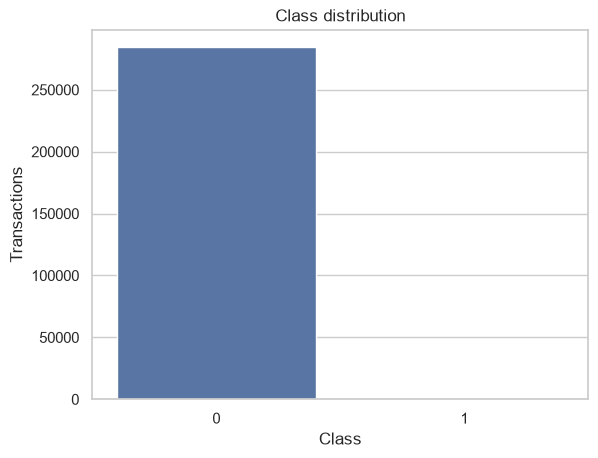

In [8]:
ax=sns.barplot(x=class_table.index.astype(str),y=class_table['count'],hue=class_table.index.astype(str),legend=False); ax.set(xlabel='Class',ylabel='Transactions',title='Class distribution'); plt.show()

## 5. Exploratory data analysis

`V1`–`V28` are anonymized PCA-derived features, while `Time` and `Amount` are not.

In [9]:
display(df.describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,94813.860,47488.146,0.000,54201.500,84692.000,139320.500,172792.000
V1,284807.0,0.000,1.959,-56.408,-0.920,0.018,1.316,2.455
V2,284807.0,0.000,1.651,-72.716,-0.599,0.065,0.804,22.058
V3,284807.0,-0.000,1.516,-48.326,-0.890,0.180,1.027,9.383
V4,284807.0,0.000,1.416,-5.683,-0.849,-0.020,0.743,16.875
V5,284807.0,0.000,1.380,-113.743,-0.692,-0.054,0.612,34.802
V6,284807.0,0.000,1.332,-26.161,-0.768,-0.274,0.399,73.302
V7,284807.0,-0.000,1.237,-43.557,-0.554,0.040,0.570,120.589
V8,284807.0,0.000,1.194,-73.217,-0.209,0.022,0.327,20.007
V9,284807.0,-0.000,1.099,-13.434,-0.643,-0.051,0.597,15.595


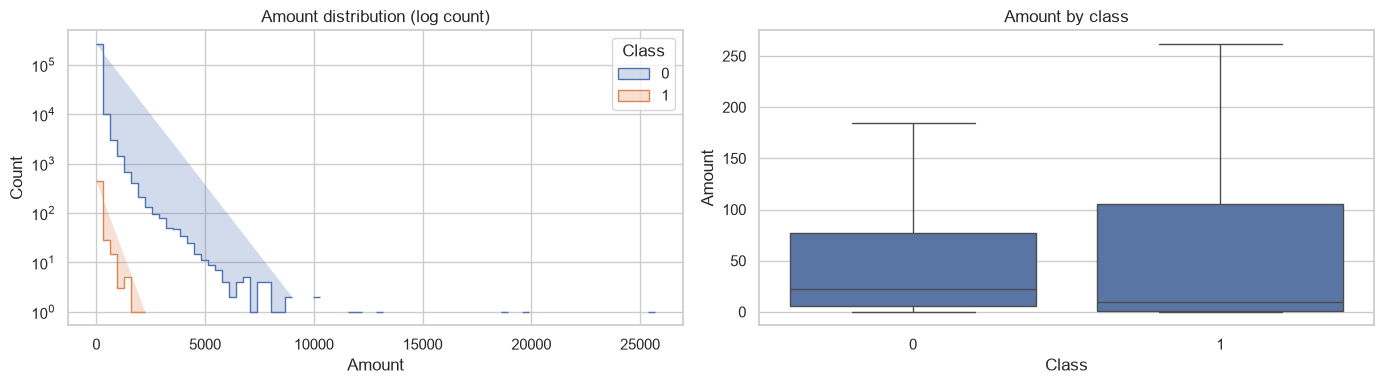

In [10]:
fig,ax=plt.subplots(1,2,figsize=(14,4)); sns.histplot(data=df,x='Amount',hue='Class',bins=80,element='step',log_scale=(False,True),ax=ax[0]); sns.boxplot(data=df,x='Class',y='Amount',showfliers=False,ax=ax[1]); ax[0].set_title('Amount distribution (log count)'); ax[1].set_title('Amount by class'); plt.tight_layout(); plt.show()

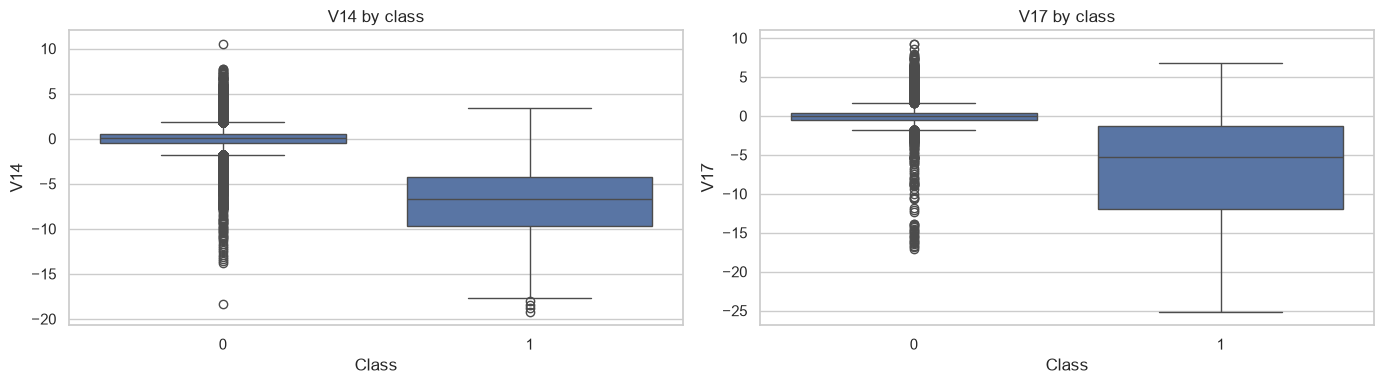

In [11]:
fig,ax=plt.subplots(1,2,figsize=(14,4)); sns.boxplot(data=df,x='Class',y='V14',ax=ax[0]); sns.boxplot(data=df,x='Class',y='V17',ax=ax[1]); ax[0].set_title('V14 by class'); ax[1].set_title('V17 by class'); plt.tight_layout(); plt.show()

## 6. Features and target

In [12]:
X=df.drop(columns='Class'); y=df.Class.astype(int); print('X shape:',X.shape); print('y shape:',y.shape); display(y.value_counts().sort_index().to_frame('count'))

X shape: (284807, 30)
y shape: (284807,)


,count
Class,
0,284315
1,492


## 7. Untouched test split and validation design

In [13]:
X_dev,X_test,y_dev,y_test=train_test_split(X,y,test_size=.20,stratify=y,random_state=SEED); cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED); folds=list(cv.split(X_dev,y_dev)); print('Development:',X_dev.shape); display(y_dev.value_counts().sort_index().to_frame('development_count')); print('Test:',X_test.shape); display(y_test.value_counts().sort_index().to_frame('test_count'))

Development: (227845, 30)


,development_count
Class,
0,227451
1,394


Test: (56962, 30)


,test_count
Class,
0,56864
1,98


## 8. Metrics, models, and repeated evaluation helpers

Scaling and resampling are fitted only within each training fold through `imblearn.Pipeline`. Precision, recall, and F1 use threshold 0.5 during CV.

In [20]:
# Leakage-safe models and incremental five-fold evaluation helpers.
scoring={'ap':'average_precision','roc_auc':'roc_auc','precision':'precision','recall':'recall','f1':'f1'}
samplers={'Original':'passthrough','RandomUnderSampler':RandomUnderSampler(random_state=SEED),'RandomOverSampler':RandomOverSampler(random_state=SEED),'SMOTE':SMOTE(random_state=SEED),'ADASYN':ADASYN(random_state=SEED)}
def make_model(name):
    if name=='Random Forest':
        # Benchmark-driven controls: one full fold was 18.83 s with this configuration.
        return RandomForestClassifier(n_estimators=30,max_depth=12,min_samples_leaf=2,n_jobs=-1,random_state=SEED)
    if name=='XGBoost': return XGBClassifier(n_estimators=50,max_depth=4,learning_rate=.1,n_jobs=-1,random_state=SEED,eval_metric='logloss',tree_method='hist')
    return LGBMClassifier(n_estimators=50,num_leaves=31,learning_rate=.08,n_jobs=-1,random_state=SEED,verbosity=-1)
def make_pipeline(name,sampling): return Pipeline([('scale',StandardScaler()),('sampler',samplers[sampling]),('model',make_model(name))])

def run_next_fixed_fold(name, sampling):
    path = RESULTS / 'fold_level_results.csv'

    # Preserve the existing checkpoint schema.
    columns = [
        'Classifier', 'Sampling', 'fold',
        'ap', 'roc_auc', 'precision', 'recall', 'f1'
    ]

    saved = (
        pd.read_csv(path)
        if path.exists()
        else pd.DataFrame(columns=columns)
    )

    # Validate the existing checkpoint before doing any training.
    missing_columns = set(columns) - set(saved.columns)
    if missing_columns:
        raise ValueError(
            f"Unexpected CSV schema. Missing columns: "
            f"{sorted(missing_columns)}"
        )

    if saved.duplicated(['Classifier', 'Sampling', 'fold']).any():
        raise ValueError(
            "Duplicate classifier/sampling/fold records detected. "
            "Inspect the CSV before continuing."
        )

    config_mask = (
        saved['Classifier'].eq(name)
        & saved['Sampling'].eq(sampling)
    )

    config_rows = saved.loc[config_mask]
    done = set(config_rows['fold'].astype(int))
    missing = [f for f in range(1, 6) if f not in done]

    if not missing:
        completed = config_rows.sort_values('fold')

        summary = {
            'Classifier': name,
            'Sampling': sampling,
            'status': 'completed',
            'completed_folds': len(completed),
        }

        for metric in scoring:
            summary[f'cv_{metric}_mean'] = completed[metric].mean()
            summary[f'cv_{metric}_std'] = completed[metric].std(ddof=1)

        result_path = RESULTS / 'resampling_cv_results.csv'

        old = (
            pd.read_csv(result_path)
            if result_path.exists()
            else pd.DataFrame()
        )

        if not old.empty:
            required = {'Classifier', 'Sampling'}
            if not required.issubset(old.columns):
                raise ValueError(
                    "Unexpected summary CSV schema; "
                    "refusing to overwrite it."
                )

            old = old.loc[
                ~(
                    old['Classifier'].eq(name)
                    & old['Sampling'].eq(sampling)
                )
            ]

        updated = pd.concat(
            [old, pd.DataFrame([summary])],
            ignore_index=True
        )
        updated.to_csv(result_path, index=False)

        return pd.DataFrame([summary])

    fold = missing[0]
    train, valid = folds[fold - 1]

    print(f'Starting {name} + {sampling}, fold {fold}/5...')

    pipe = make_pipeline(name, sampling)
    start = perf_counter()

    pipe.fit(X_dev.iloc[train], y_dev.iloc[train])
    prob = pipe.predict_proba(X_dev.iloc[valid])[:, 1]
    pred = (prob >= 0.5).astype(int)

    row = {
        'Classifier': name,
        'Sampling': sampling,
        'fold': fold,
        'ap': average_precision_score(y_dev.iloc[valid], prob),
        'roc_auc': roc_auc_score(y_dev.iloc[valid], prob),
        'precision': precision_score(
            y_dev.iloc[valid], pred, zero_division=0
        ),
        'recall': recall_score(
            y_dev.iloc[valid], pred, zero_division=0
        ),
        'f1': f1_score(
            y_dev.iloc[valid], pred, zero_division=0
        ),
    }

    row['elapsed_seconds'] = perf_counter() - start

    # Append only the newly completed fold.
    updated = pd.concat(
        [saved, pd.DataFrame([{
            key: row[key] for key in columns
        }])],
        ignore_index=True
    )
    updated.to_csv(path, index=False)

    print(f'Completed fold {fold}/5. Rerun this cell for the next fold.')

    return pd.DataFrame([row])


In [21]:
saved = pd.read_csv(RESULTS / 'fold_level_results.csv')

print("Total checkpoint rows:", len(saved))

print(
    saved.groupby(['Classifier', 'Sampling'])['fold']
    .agg(['count', 'nunique', 'min', 'max'])
)

Total checkpoint rows: 75
                                  count  nunique  min  max
Classifier    Sampling                                    
LightGBM      ADASYN                  5        5    1    5
              Original                5        5    1    5
              RandomOverSampler       5        5    1    5
              RandomUnderSampler      5        5    1    5
              SMOTE                   5        5    1    5
Random Forest ADASYN                  5        5    1    5
              Original                5        5    1    5
              RandomOverSampler       5        5    1    5
              RandomUnderSampler      5        5    1    5
              SMOTE                   5        5    1    5
XGBoost       ADASYN                  5        5    1    5
              Original                5        5    1    5
              RandomOverSampler       5        5    1    5
              RandomUnderSampler      5        5    1    5
              SMOTE           

## 8A. Random Forest runtime diagnosis and pilot

The original configuration trained five serial full-data folds with unconstrained trees. A 20%-development pilot and one full-data fold benchmark are recorded below. Pilot metrics validate execution only; they are not main-study results.

In [22]:
from sklearn.model_selection import train_test_split
X_pilot,_,y_pilot,_=train_test_split(X_dev,y_dev,train_size=.20,stratify=y_dev,random_state=SEED)
train,valid=next(StratifiedKFold(5,shuffle=True,random_state=SEED).split(X_pilot,y_pilot))
pilot=make_pipeline('Random Forest','Original'); start=perf_counter(); pilot.fit(X_pilot.iloc[train],y_pilot.iloc[train]); pilot_prob=pilot.predict_proba(X_pilot.iloc[valid])[:,1]
pilot_table=pd.DataFrame([{'experiment':'pilot (20% development, one fold)','train_rows':len(train),'validation_rows':len(valid),'elapsed_seconds':perf_counter()-start,'AP':average_precision_score(y_pilot.iloc[valid],pilot_prob),'ROC_AUC':roc_auc_score(y_pilot.iloc[valid],pilot_prob)}]); display(pilot_table.round(4)); pilot_table.to_csv(RESULTS/'runtime_pilot.csv',index=False)

,experiment,train_rows,validation_rows,elapsed_seconds,AP,ROC_AUC
0,"pilot (20% development, one fold)",36455,9114,1.5018,0.6759,0.9345


## 9. Baseline experiments: original imbalanced data

In [23]:
from pathlib import Path
import pandas as pd

print("Notebook results directory:", RESULTS.resolve())

path = RESULTS / "fold_level_results.csv"
print("CSV path:", path.resolve())
print("File exists:", path.exists())

if path.exists():
    saved_debug = pd.read_csv(path)

    expected_columns = [
        'stage', 'configuration_id', 'Classifier', 'Sampling',
        'fold', 'ap', 'roc_auc', 'precision', 'recall',
        'f1', 'elapsed_seconds', 'status'
    ]

    print("\nActual columns:")
    print(saved_debug.columns.tolist())

    print("\nMissing expected columns:")
    print(sorted(set(expected_columns) - set(saved_debug.columns)))

    print("\nShape:", saved_debug.shape)
    display(saved_debug.head(10))
else:
    print("CSV not found at this path.")

Notebook results directory: /Users/deepansh/Desktop/Final_proj/results
CSV path: /Users/deepansh/Desktop/Final_proj/results/fold_level_results.csv
File exists: True

Actual columns:
['Classifier', 'Sampling', 'fold', 'ap', 'roc_auc', 'precision', 'recall', 'f1']

Missing expected columns:
['configuration_id', 'elapsed_seconds', 'stage', 'status']

Shape: (75, 8)


,Classifier,Sampling,fold,ap,roc_auc,precision,recall,f1
0,Random Forest,Original,1,0.859754,0.954210,0.950820,0.743590,0.834532
1,Random Forest,Original,2,0.807400,0.903546,1.000000,0.759494,0.863309
2,Random Forest,Original,3,0.823224,0.929046,0.952381,0.759494,0.845070
3,Random Forest,Original,4,0.889548,0.967636,0.890411,0.822785,0.855263
4,Random Forest,Original,5,0.811131,0.941683,0.953125,0.772152,0.853147
5,Random Forest,RandomUnderSampler,1,0.760546,0.985644,0.040606,0.961538,0.077922
6,Random Forest,RandomUnderSampler,2,0.698215,0.970541,0.049455,0.860759,0.093535
7,Random Forest,RandomUnderSampler,3,0.703392,0.970802,0.071061,0.873418,0.131429
8,Random Forest,RandomUnderSampler,4,0.746132,0.985062,0.052192,0.949367,0.098945
9,Random Forest,RandomUnderSampler,5,0.740616,0.974196,0.047809,0.911392,0.090852


In [24]:
result=run_next_fixed_fold('Random Forest','Original')
display(result.round(4))

,Classifier,Sampling,status,completed_folds,cv_ap_mean,cv_ap_std,cv_roc_auc_mean,cv_roc_auc_std,cv_precision_mean,cv_precision_std,cv_recall_mean,cv_recall_std,cv_f1_mean,cv_f1_std
0,Random Forest,Original,completed,5,0.8382,0.0354,0.9392,0.0246,0.9493,0.0389,0.7715,0.0304,0.8503,0.0109


In [25]:
result=run_next_fixed_fold('XGBoost','Original')
display(result.round(4))

,Classifier,Sampling,status,completed_folds,cv_ap_mean,cv_ap_std,cv_roc_auc_mean,cv_roc_auc_std,cv_precision_mean,cv_precision_std,cv_recall_mean,cv_recall_std,cv_f1_mean,cv_f1_std
0,XGBoost,Original,completed,5,0.8204,0.0112,0.9804,0.0139,0.9422,0.0456,0.7386,0.0412,0.8265,0.0156


In [26]:
result=run_next_fixed_fold('LightGBM','Original')
display(result.round(4))

,Classifier,Sampling,status,completed_folds,cv_ap_mean,cv_ap_std,cv_roc_auc_mean,cv_roc_auc_std,cv_precision_mean,cv_precision_std,cv_recall_mean,cv_recall_std,cv_f1_mean,cv_f1_std
0,LightGBM,Original,completed,5,0.5642,0.1349,0.8117,0.0902,0.3527,0.2473,0.683,0.0603,0.4383,0.203


## 10. Fixed-parameter resampling experiments

Each following cell is one of the 15 model–sampling configurations. The original cases above are baselines; they are not duplicated here.

### Random Forest + RandomUnderSampler

In [27]:
result=run_next_fixed_fold('Random Forest','RandomUnderSampler')
display(result.round(4))

,Classifier,Sampling,status,completed_folds,cv_ap_mean,cv_ap_std,cv_roc_auc_mean,cv_roc_auc_std,cv_precision_mean,cv_precision_std,cv_recall_mean,cv_recall_std,cv_f1_mean,cv_f1_std
0,Random Forest,RandomUnderSampler,completed,5,0.7298,0.0275,0.9772,0.0075,0.0522,0.0114,0.9113,0.0446,0.0985,0.0199


### Random Forest + RandomOverSampler

In [28]:
result=run_next_fixed_fold('Random Forest','RandomOverSampler')
display(result.round(4))

,Classifier,Sampling,status,completed_folds,cv_ap_mean,cv_ap_std,cv_roc_auc_mean,cv_roc_auc_std,cv_precision_mean,cv_precision_std,cv_recall_mean,cv_recall_std,cv_f1_mean,cv_f1_std
0,Random Forest,RandomOverSampler,completed,5,0.8295,0.02,0.9492,0.0145,0.9334,0.0301,0.7614,0.0395,0.8376,0.0159


### Random Forest + SMOTE

In [29]:
result=run_next_fixed_fold('Random Forest','SMOTE')
display(result.round(4))

,Classifier,Sampling,status,completed_folds,cv_ap_mean,cv_ap_std,cv_roc_auc_mean,cv_roc_auc_std,cv_precision_mean,cv_precision_std,cv_recall_mean,cv_recall_std,cv_f1_mean,cv_f1_std
0,Random Forest,SMOTE,completed,5,0.8421,0.0291,0.9699,0.0236,0.882,0.04,0.7944,0.0467,0.8343,0.0176


### Random Forest + ADASYN

In [30]:
result=run_next_fixed_fold('Random Forest','ADASYN')
display(result.round(4))

,Classifier,Sampling,status,completed_folds,cv_ap_mean,cv_ap_std,cv_roc_auc_mean,cv_roc_auc_std,cv_precision_mean,cv_precision_std,cv_recall_mean,cv_recall_std,cv_f1_mean,cv_f1_std
0,Random Forest,ADASYN,completed,5,0.8201,0.0258,0.9613,0.0191,0.8628,0.0332,0.7843,0.0503,0.8202,0.0213


### XGBoost + RandomUnderSampler

In [31]:
result=run_next_fixed_fold('XGBoost','RandomUnderSampler')
display(result.round(4))

,Classifier,Sampling,status,completed_folds,cv_ap_mean,cv_ap_std,cv_roc_auc_mean,cv_roc_auc_std,cv_precision_mean,cv_precision_std,cv_recall_mean,cv_recall_std,cv_f1_mean,cv_f1_std
0,XGBoost,RandomUnderSampler,completed,5,0.7243,0.0358,0.9809,0.0093,0.0419,0.0056,0.9189,0.0385,0.0801,0.0102


### XGBoost + RandomOverSampler

In [32]:
result=run_next_fixed_fold('XGBoost','RandomOverSampler')
display(result.round(4))

,Classifier,Sampling,status,completed_folds,cv_ap_mean,cv_ap_std,cv_roc_auc_mean,cv_roc_auc_std,cv_precision_mean,cv_precision_std,cv_recall_mean,cv_recall_std,cv_f1_mean,cv_f1_std
0,XGBoost,RandomOverSampler,completed,5,0.7979,0.0389,0.9806,0.0114,0.3333,0.0305,0.8579,0.03,0.4789,0.0272


### XGBoost + SMOTE

In [33]:
result=run_next_fixed_fold('XGBoost','SMOTE')
display(result.round(4))

,Classifier,Sampling,status,completed_folds,cv_ap_mean,cv_ap_std,cv_roc_auc_mean,cv_roc_auc_std,cv_precision_mean,cv_precision_std,cv_recall_mean,cv_recall_std,cv_f1_mean,cv_f1_std
0,XGBoost,SMOTE,completed,5,0.7976,0.0661,0.9803,0.0114,0.1589,0.0171,0.8706,0.0393,0.2682,0.0228


### XGBoost + ADASYN

In [34]:
result=run_next_fixed_fold('XGBoost','ADASYN')
display(result.round(4))

,Classifier,Sampling,status,completed_folds,cv_ap_mean,cv_ap_std,cv_roc_auc_mean,cv_roc_auc_std,cv_precision_mean,cv_precision_std,cv_recall_mean,cv_recall_std,cv_f1_mean,cv_f1_std
0,XGBoost,ADASYN,completed,5,0.7555,0.0622,0.9791,0.0101,0.0713,0.0031,0.8935,0.0477,0.1319,0.005


### LightGBM + RandomUnderSampler

In [35]:
result=run_next_fixed_fold('LightGBM','RandomUnderSampler')
display(result.round(4))

,Classifier,Sampling,status,completed_folds,cv_ap_mean,cv_ap_std,cv_roc_auc_mean,cv_roc_auc_std,cv_precision_mean,cv_precision_std,cv_recall_mean,cv_recall_std,cv_f1_mean,cv_f1_std
0,LightGBM,RandomUnderSampler,completed,5,0.7376,0.0293,0.9816,0.0105,0.0409,0.0051,0.9189,0.0424,0.0783,0.0093


### LightGBM + RandomOverSampler

In [36]:
result=run_next_fixed_fold('LightGBM','RandomOverSampler')
display(result.round(4))

,Classifier,Sampling,status,completed_folds,cv_ap_mean,cv_ap_std,cv_roc_auc_mean,cv_roc_auc_std,cv_precision_mean,cv_precision_std,cv_recall_mean,cv_recall_std,cv_f1_mean,cv_f1_std
0,LightGBM,RandomOverSampler,completed,5,0.7752,0.0461,0.9731,0.0176,0.7238,0.0377,0.8325,0.0501,0.7726,0.0151


### LightGBM + SMOTE

In [37]:
result=run_next_fixed_fold('LightGBM','SMOTE')
display(result.round(4))

,Classifier,Sampling,status,completed_folds,cv_ap_mean,cv_ap_std,cv_roc_auc_mean,cv_roc_auc_std,cv_precision_mean,cv_precision_std,cv_recall_mean,cv_recall_std,cv_f1_mean,cv_f1_std
0,LightGBM,SMOTE,completed,5,0.7652,0.0428,0.9808,0.0118,0.3931,0.0348,0.863,0.036,0.5391,0.0317


### LightGBM + ADASYN

In [38]:
result=run_next_fixed_fold('LightGBM','ADASYN')
display(result.round(4))

,Classifier,Sampling,status,completed_folds,cv_ap_mean,cv_ap_std,cv_roc_auc_mean,cv_roc_auc_std,cv_precision_mean,cv_precision_std,cv_recall_mean,cv_recall_std,cv_f1_mean,cv_f1_std
0,LightGBM,ADASYN,completed,5,0.7716,0.0662,0.9785,0.0091,0.2472,0.0253,0.863,0.0403,0.3834,0.0295


## 11. Fixed comparison table

In [40]:

# Load existing checkpoints only; no experiments are rerun.
fixed_results = pd.read_csv(RESULTS / 'resampling_cv_results.csv')
fold_level = pd.read_csv(RESULTS / 'fold_level_results.csv')

# Count distinct completed folds for each configuration.
fold_counts = (
    fold_level.groupby(['Classifier', 'Sampling'])['fold']
    .nunique()
    .rename('verified_completed_folds')
    .reset_index()
)

# Remove any previously saved count/status columns before merging,
# so pandas cannot create ambiguous _x/_y column names.
fixed_results = fixed_results.drop(
    columns=['completed_folds', 'verified_completed_folds',
             'status', 'status_x', 'status_y'],
    errors='ignore'
)

verified_fixed = fixed_results.merge(
    fold_counts,
    on=['Classifier', 'Sampling'],
    how='left',
    validate='one_to_one'
)

verified_fixed['verified_completed_folds'] = (
    verified_fixed['verified_completed_folds']
    .fillna(0)
    .astype(int)
)

verified_fixed['status'] = np.where(
    verified_fixed['verified_completed_folds'].eq(5),
    'completed',
    'incomplete'
)

display(
    verified_fixed.sort_values('cv_ap_mean', ascending=False).round(4)
)

print(
    'Verified completed configurations:',
    int(verified_fixed['status'].eq('completed').sum()),
    'of',
    len(verified_fixed)
)

verified_fixed.to_csv(
    RESULTS / 'verified_fixed_comparison.csv',
    index=False
)


,Classifier,Sampling,time_seconds,cv_ap_mean,cv_ap_std,cv_roc_auc_mean,cv_roc_auc_std,cv_precision_mean,cv_precision_std,cv_recall_mean,cv_recall_std,cv_f1_mean,cv_f1_std,verified_completed_folds,status
5,Random Forest,SMOTE,NaN,0.8421,0.0291,0.9699,0.0236,0.8820,0.0400,0.7944,0.0467,0.8343,0.0176,5,completed
0,Random Forest,Original,NaN,0.8382,0.0354,0.9392,0.0246,0.9493,0.0389,0.7715,0.0304,0.8503,0.0109,5,completed
4,Random Forest,RandomOverSampler,NaN,0.8295,0.0200,0.9492,0.0145,0.9334,0.0301,0.7614,0.0395,0.8376,0.0159,5,completed
1,XGBoost,Original,NaN,0.8204,0.0112,0.9804,0.0139,0.9422,0.0456,0.7386,0.0412,0.8265,0.0156,5,completed
6,Random Forest,ADASYN,NaN,0.8201,0.0258,0.9613,0.0191,0.8628,0.0332,0.7843,0.0503,0.8202,0.0213,5,completed
8,XGBoost,RandomOverSampler,NaN,0.7979,0.0389,0.9806,0.0114,0.3333,0.0305,0.8579,0.0300,0.4789,0.0272,5,completed
9,XGBoost,SMOTE,NaN,0.7976,0.0661,0.9803,0.0114,0.1589,0.0171,0.8706,0.0393,0.2682,0.0228,5,completed
12,LightGBM,RandomOverSampler,NaN,0.7752,0.0461,0.9731,0.0176,0.7238,0.0377,0.8325,0.0501,0.7726,0.0151,5,completed
14,LightGBM,ADASYN,NaN,0.7716,0.0662,0.9785,0.0091,0.2472,0.0253,0.8630,0.0403,0.3834,0.0295,5,completed
13,LightGBM,SMOTE,NaN,0.7652,0.0428,0.9808,0.0118,0.3931,0.0348,0.8630,0.0360,0.5391,0.0317,5,completed


Verified completed configurations: 15 of 15


## 12. Hyperparameter tuning

Budget: two very small estimator-size candidates (10 and 20), selected so all 15 five-fold searches can run in this environment per resampled configuration and four candidates for original-data configurations (including a meaningful imbalance-control setting). AP selects the best candidate; all metrics are saved.

In [41]:
def tune_grid(name,sampling):
    grid={'model__n_estimators':[10,20]}
    if sampling=='Original':
        if name in ('Random Forest','LightGBM'): grid['model__class_weight']=[None,'balanced']
        else: grid['model__scale_pos_weight']=[1,float(y_dev.value_counts()[0]/y_dev.value_counts()[1])]
    return grid
def tune_one(name,sampling):
    start=perf_counter(); g=GridSearchCV(make_pipeline(name,sampling),tune_grid(name,sampling),scoring=scoring,refit='ap',cv=folds,n_jobs=1,error_score='raise'); g.fit(X_dev,y_dev); r=g.cv_results_; i=g.best_index_; out={'Classifier':name,'Sampling':sampling,'best_parameters':json.dumps(g.best_params_),'tuning_time_seconds':perf_counter()-start}
    for metric in scoring: out[f'cv_{metric}_mean']=r[f'mean_test_{metric}'][i]; out[f'cv_{metric}_std']=r[f'std_test_{metric}'][i]
    return out
print('Tuning helpers ready.')

Tuning helpers ready.


### Tune all sampling strategies: Random Forest

In [44]:
tuned_rows = []
for sampling in samplers:
    print('Starting tuning: Random Forest +',sampling)
    result=tune_one('Random Forest',sampling); tuned_rows.append(result)
    display(pd.DataFrame([result]).round(4))
    print('Completed tuning: Random Forest +',sampling)

Starting tuning: Random Forest + Original


,Classifier,Sampling,best_parameters,tuning_time_seconds,cv_ap_mean,cv_ap_std,cv_roc_auc_mean,cv_roc_auc_std,cv_precision_mean,cv_precision_std,cv_recall_mean,cv_recall_std,cv_f1_mean,cv_f1_std
0,Random Forest,Original,"{""model__class_weight"": null, ""model__n_estima...",85.3307,0.8283,0.0283,0.9715,0.0131,0.9416,0.0482,0.7588,0.0269,0.8389,0.0065


Completed tuning: Random Forest + Original
Starting tuning: Random Forest + RandomUnderSampler


,Classifier,Sampling,best_parameters,tuning_time_seconds,cv_ap_mean,cv_ap_std,cv_roc_auc_mean,cv_roc_auc_std,cv_precision_mean,cv_precision_std,cv_recall_mean,cv_recall_std,cv_f1_mean,cv_f1_std
0,Random Forest,RandomUnderSampler,"{""model__n_estimators"": 20}",3.1644,0.6973,0.0292,0.9796,0.0058,0.049,0.0077,0.8935,0.0314,0.0928,0.0135


Completed tuning: Random Forest + RandomUnderSampler
Starting tuning: Random Forest + RandomOverSampler


...

Completed tuning: Random Forest + RandomOverSampler
Starting tuning: Random Forest + SMOTE


,Classifier,Sampling,best_parameters,tuning_time_seconds,cv_ap_mean,cv_ap_std,cv_roc_auc_mean,cv_roc_auc_std,cv_precision_mean,cv_precision_std,cv_recall_mean,cv_recall_std,cv_f1_mean,cv_f1_std
0,Random Forest,SMOTE,"{""model__n_estimators"": 20}",115.7669,0.7871,0.0178,0.9759,0.0123,0.5175,0.0607,0.8122,0.0461,0.6285,0.0414


Completed tuning: Random Forest + SMOTE
Starting tuning: Random Forest + ADASYN


,Classifier,Sampling,best_parameters,tuning_time_seconds,cv_ap_mean,cv_ap_std,cv_roc_auc_mean,cv_roc_auc_std,cv_precision_mean,cv_precision_std,cv_recall_mean,cv_recall_std,cv_f1_mean,cv_f1_std
0,Random Forest,ADASYN,"{""model__n_estimators"": 20}",104.3,0.7383,0.0341,0.9738,0.0143,0.1887,0.0618,0.8401,0.0396,0.3023,0.0725


Completed tuning: Random Forest + ADASYN


### Tune all sampling strategies: XGBoost

In [ ]:
for sampling in samplers:
    print('Starting tuning: XGBoost +',sampling)
    result=tune_one('XGBoost',sampling); tuned_rows.append(result)
    display(pd.DataFrame([result]).round(4))
    print('Completed tuning: XGBoost +',sampling)

### Tune all sampling strategies: LightGBM

In [ ]:
for sampling in samplers:
    print('Starting tuning: LightGBM +',sampling)
    result=tune_one('LightGBM',sampling); tuned_rows.append(result)
    display(pd.DataFrame([result]).round(4))
    print('Completed tuning: LightGBM +',sampling)

## 13. Comprehensive tuned comparison

In [ ]:
tuned_results=pd.DataFrame(tuned_rows); tuned_results['rank_ap']=tuned_results.cv_ap_mean.rank(ascending=False,method='min').astype(int); tuned_results['rank_roc_auc']=tuned_results.cv_roc_auc_mean.rank(ascending=False,method='min').astype(int); tuned_results=tuned_results.sort_values('rank_ap'); display(tuned_results.round(4)); tuned_results.to_csv(RESULTS/'tuning_results.csv',index=False); all_results=pd.concat([fixed_results.assign(experiment='fixed'),tuned_results.assign(experiment='tuned')],ignore_index=True,sort=False); all_results.to_csv(RESULTS/'all_experiments_summary.csv',index=False)

## 14. Model rankings

In [ ]:
display(tuned_results[['Classifier','Sampling','cv_ap_mean','cv_ap_std','rank_ap']].sort_values('rank_ap').round(4))

In [ ]:
display(tuned_results[['Classifier','Sampling','cv_roc_auc_mean','cv_roc_auc_std','rank_roc_auc']].sort_values('rank_roc_auc').round(4))

## 15. Precision–recall curves

Top configurations are selected only by development CV AP. PR curves are particularly informative here because fraud is rare.

In [ ]:
shortlist=tuned_results.head(3).copy()
def oof_prob(row):
    p=make_pipeline(row.Classifier,row.Sampling); p.set_params(**json.loads(row.best_parameters)); out=np.zeros(len(X_dev))
    for train,valid in folds: p.fit(X_dev.iloc[train],y_dev.iloc[train]); out[valid]=p.predict_proba(X_dev.iloc[valid])[:,1]
    return out
oof={f'{r.Classifier} | {r.Sampling}':oof_prob(r) for _,r in shortlist.iterrows()}
fig,ax=plt.subplots(figsize=(7,5))
for label,prob in oof.items():
    precision,recall,_=precision_recall_curve(y_dev,prob); ax.plot(recall,precision,label=f'{label} (AP={average_precision_score(y_dev,prob):.3f})')
ax.axhline(y_dev.mean(),color='k',ls='--',label=f'Prevalence={y_dev.mean():.4f}'); ax.set(xlabel='Recall',ylabel='Precision',title='Development-only OOF PR curves',xlim=(0,1),ylim=(0,1)); ax.legend(fontsize=8); plt.show()

## 16. ROC curves

In [ ]:
fig,ax=plt.subplots(figsize=(7,5))
for label,prob in oof.items():
    fpr,tpr,_=roc_curve(y_dev,prob); ax.plot(fpr,tpr,label=f'{label} (AUC={roc_auc_score(y_dev,prob):.3f})')
ax.plot([0,1],[0,1],'k--'); ax.set(xlabel='False positive rate',ylabel='True positive rate',title='Development-only OOF ROC curves',xlim=(0,1),ylim=(0,1)); ax.legend(fontsize=8); plt.show()

## 17. Threshold analysis

The AP leader uses development-only OOF probabilities. The operating threshold maximizes development OOF F1; 0.5 is shown for comparison.

In [ ]:
selected=shortlist.iloc[0]; selected_label=f'{selected.Classifier} | {selected.Sampling}'; selected_oof=oof[selected_label]; threshold_rows=[]
for threshold in np.round(np.arange(.05,.951,.01),2):
    pred=(selected_oof>=threshold).astype(int); tn,fp,fn,tp=confusion_matrix(y_dev,pred,labels=[0,1]).ravel(); threshold_rows.append({'threshold':threshold,'precision':precision_score(y_dev,pred,zero_division=0),'recall':recall_score(y_dev,pred,zero_division=0),'f1':f1_score(y_dev,pred,zero_division=0),'false_positives':fp,'false_negatives':fn,'false_positive_rate':fp/(fp+tn)})
threshold_results=pd.DataFrame(threshold_rows); selected_threshold=float(threshold_results.loc[threshold_results.f1.idxmax(),'threshold']); print('Selected configuration:',selected_label,'threshold:',selected_threshold)

In [ ]:
display(threshold_results[threshold_results.threshold.isin([.5,selected_threshold])].round(4)); threshold_results.to_csv(RESULTS/'threshold_analysis.csv',index=False)

In [ ]:
fig,ax=plt.subplots(figsize=(9,4)); [ax.plot(threshold_results.threshold,threshold_results[m],label=m) for m in ['precision','recall','f1']]; ax.axvline(.5,color='grey',ls='--',label='0.50'); ax.axvline(selected_threshold,color='red',ls='--',label=f'F1-selected {selected_threshold:.2f}'); ax.set(xlabel='Threshold',ylabel='Score',ylim=(0,1),title='Development-only threshold trade-off'); ax.legend(); plt.show()

## 18. Final untouched test evaluation

In [ ]:
final_pipe=make_pipeline(selected.Classifier,selected.Sampling); final_pipe.set_params(**json.loads(selected.best_parameters)); final_pipe.fit(X_dev,y_dev); test_prob=final_pipe.predict_proba(X_test)[:,1]
def test_row(threshold):
    pred=(test_prob>=threshold).astype(int); tn,fp,fn,tp=confusion_matrix(y_test,pred,labels=[0,1]).ravel(); return {'threshold':threshold,'test_ap':average_precision_score(y_test,test_prob),'test_roc_auc':roc_auc_score(y_test,test_prob),'precision':precision_score(y_test,pred,zero_division=0),'recall':recall_score(y_test,pred,zero_division=0),'f1':f1_score(y_test,pred,zero_division=0),'true_negatives':tn,'false_positives':fp,'false_negatives':fn,'true_positives':tp}
final_results=pd.DataFrame([test_row(selected_threshold),test_row(.5)]); display(final_results.round(4)); final_results.to_csv(RESULTS/'final_test_results.csv',index=False)

In [ ]:
cm=confusion_matrix(y_test,(test_prob>=selected_threshold).astype(int)); sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=['Legitimate','Fraud'],yticklabels=['Legitimate','Fraud']); plt.title(f'Untouched test confusion matrix at {selected_threshold:.2f}'); plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.show()

## 19. Research findings and limitations

In [ ]:
ap_leader=tuned_results.iloc[0]; auc_leader=tuned_results.sort_values('cv_roc_auc_mean',ascending=False).iloc[0]; test_selected=final_results.iloc[0]; findings=f'''AP leader: {ap_leader.Classifier} | {ap_leader.Sampling} ({ap_leader.cv_ap_mean:.4f} ± {ap_leader.cv_ap_std:.4f}).\nROC-AUC leader: {auc_leader.Classifier} | {auc_leader.Sampling} ({auc_leader.cv_roc_auc_mean:.4f} ± {auc_leader.cv_roc_auc_std:.4f}).\nFinal test at development-selected threshold {selected_threshold:.2f}: AP={test_selected.test_ap:.4f}, ROC-AUC={test_selected.test_roc_auc:.4f}, precision={test_selected.precision:.4f}, recall={test_selected.recall:.4f}, F1={test_selected.f1:.4f}, FP={int(test_selected.false_positives)}, FN={int(test_selected.false_negatives)}.\n\nLimitations: results use anonymized features and one historical dataset; external validation, temporal drift, and financial costs are not assessed.'''; print(findings); (RESULTS/'research_findings.md').write_text(findings)

## 20. Save artifacts and completion summary

In [ ]:
print('Notebook workflow complete. Actual artifacts:'); [print('-',p.name) for p in sorted(RESULTS.iterdir())]